In [4]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

from imblearn.over_sampling import SMOTE

In [5]:
#Load Dataset
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender   Age  \
0          1    15634602  Hargrave          619    France  Female  42.0   
1          2    15647311      Hill          608     Spain  Female  41.0   
2          3    15619304      Onio          502    France  Female  42.0   
3          4    15701354      Boni          699    France  Female  39.0   
4          5    15737888  Mitchell          850     Spain  Female  43.0   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3        

In [6]:
#Check Missing Values
print(df.isnull().sum())

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             3
Age                3
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [7]:
#Handle Missing Values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Exited
0    7963
1    2037
Name: count, dtype: int64


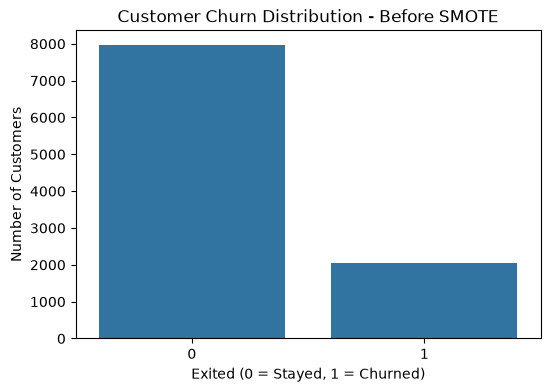

In [8]:
#Check Class Imbalance
print(df["Exited"].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(x="Exited", data=df)
plt.title("Customer Churn Distribution - Before SMOTE")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

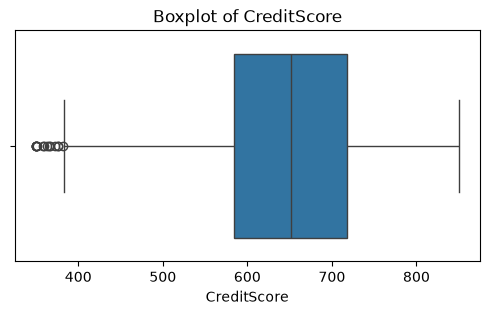

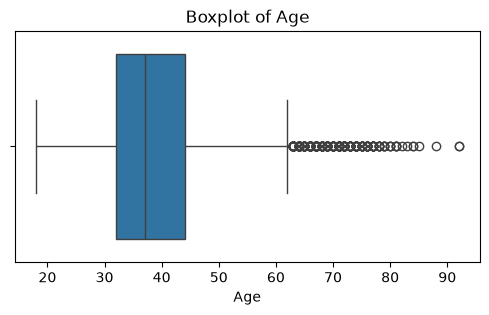

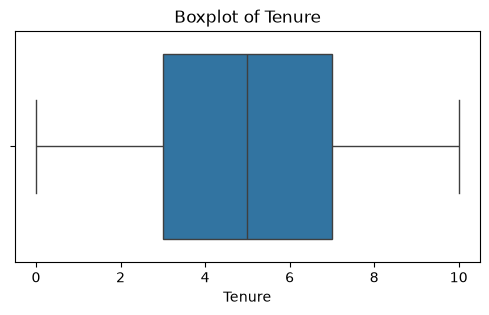

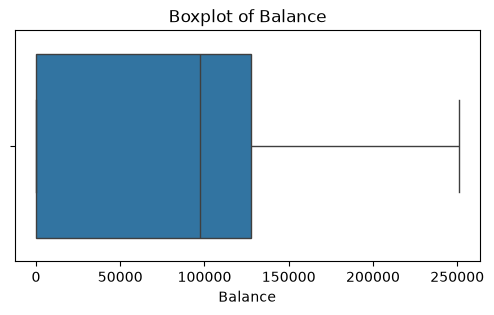

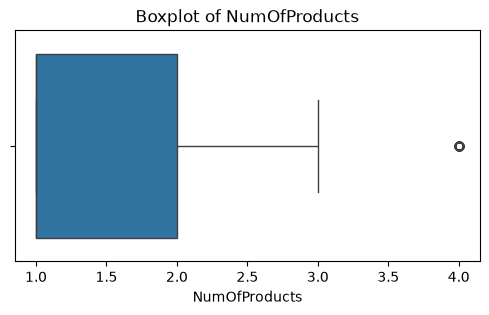

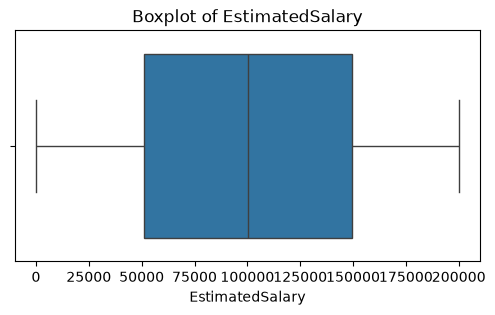

In [9]:
#Outlier Detection
numeric_columns = [
    "CreditScore", "Age", "Tenure",
    "Balance", "NumOfProducts", "EstimatedSalary"
]

for column in numeric_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[column])
    plt.title("Boxplot of " + column)
    plt.show()

In [10]:
#Separate X and y
X = df.drop(
    ["RowNumber", "CustomerId", "Surname", "Exited"],
    axis=1
)

y = df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 10)
y shape: (10000,)


In [11]:
#Separate X and y
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True
)

print("Shape after One-Hot Encoding:", X.shape)
print(X.head())

Shape after One-Hot Encoding: (10000, 11)
   CreditScore   Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619  42.0       2       0.00              1          1   
1          608  41.0       1   83807.86              1          0   
2          502  42.0       8  159660.80              3          1   
3          699  39.0       1       0.00              2          0   
4          850  43.0       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88              False            False   
1               1        112542.58              False             True   
2               0        113931.57              False            False   
3               0         93826.63              False            False   
4               1         79084.10              False             True   

   Gender_Male  
0        False  
1        False  
2        False  
3        False  
4        Fals

In [12]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (8000, 11)
Testing data : (2000, 11)

Training class distribution:
Exited
0    6370
1    1630
Name: count, dtype: int64

Testing class distribution:
Exited
0    1593
1     407
Name: count, dtype: int64


In [13]:
#Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled.")
print("Testing data scaled.")

Training data scaled.
Testing data scaled.


In [14]:
#Apply SMOTE Only to Training Data
print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

Before SMOTE:
Exited
0    6370
1    1630
Name: count, dtype: int64

After SMOTE:
Exited
1    6370
0    6370
Name: count, dtype: int64


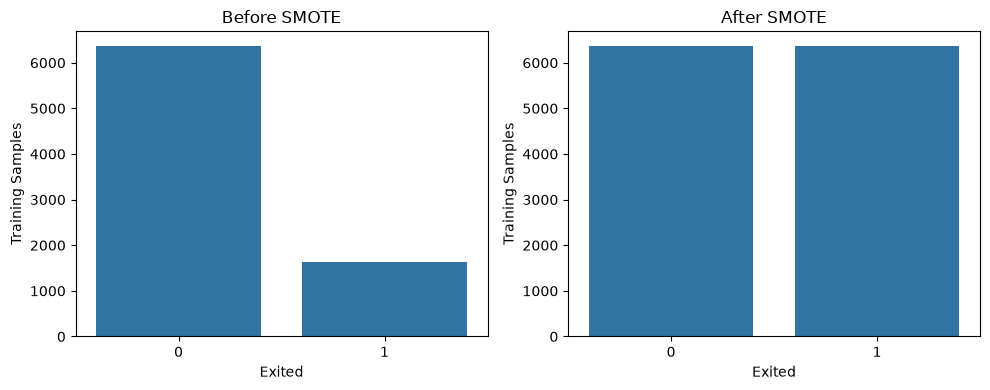

In [15]:
#Visualize Before and After SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10,4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Exited")
axes[0].set_ylabel("Training Samples")

sns.countplot(x=y_train_balanced, ax=axes[1])
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Exited")
axes[1].set_ylabel("Training Samples")

plt.tight_layout()
plt.show()

In [16]:
#Gaussian Naive Bayes
nb_model = GaussianNB()

nb_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


In [17]:
#Prediction
y_pred = nb_model.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

First 20 predictions:
[0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 1 1]

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]


In [18]:
#Evaluation
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.7135
Precision: 0.3850415512465374
Recall   : 0.683046683046683
F1 Score : 0.4924712134632418

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.68      0.49       407

    accuracy                           0.71      2000
   macro avg       0.64      0.70      0.65      2000
weighted avg       0.79      0.71      0.74      2000



[[1149  444]
 [ 129  278]]


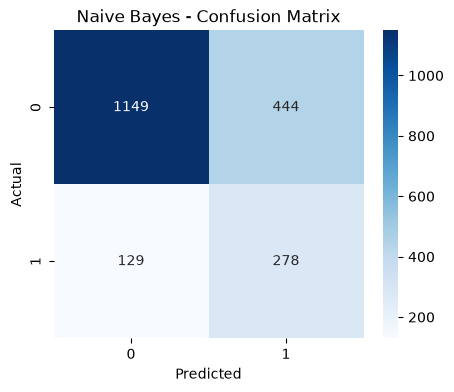

In [19]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

In [20]:
#Naive Bayes Before SMOTE
nb_baseline = GaussianNB()

nb_baseline.fit(
    X_train_scaled,
    y_train
)

y_pred_baseline = nb_baseline.predict(X_test_scaled)

print("Naive Bayes - Before SMOTE")
print(classification_report(y_test, y_pred_baseline))

Naive Bayes - Before SMOTE
              precision    recall  f1-score   support

           0       0.85      0.94      0.89      1593
           1       0.60      0.35      0.44       407

    accuracy                           0.82      2000
   macro avg       0.72      0.64      0.67      2000
weighted avg       0.80      0.82      0.80      2000



In [21]:
#Compare Before and After SMOTE
comparison = pd.DataFrame({
    "Model": [
        "Naive Bayes - Before SMOTE",
        "Naive Bayes - After SMOTE"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred)
    ],
    "Precision (Churn)": [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred)
    ],
    "Recall (Churn)": [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred)
    ],
    "F1 (Churn)": [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred)
    ]
})

print(comparison)

                        Model  Accuracy  Precision (Churn)  Recall (Churn)  \
0  Naive Bayes - Before SMOTE    0.8200           0.600000        0.346437   
1   Naive Bayes - After SMOTE    0.7135           0.385042        0.683047   

   F1 (Churn)  
0    0.439252  
1    0.492471  
